# Forest Proximity Tutorial (RF, ExtraTrees, RotationForest, IsolationForest)

This notebook demonstrates how to generate forest-based proximities using `forestgap`, embed them with PHATE, and compare embeddings across model families.

Workflow:
1. Set `TASK_TYPE` to `classification` or `regression` (single switch at top).
2. Load dataset and split train/test.
3. Build proximities for each forest model.
4. Compute PHATE embedding from each model's proximity matrix.
5. Compare all embeddings in one final subplot figure.

In [1]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    IsolationForest,
)

from forestgap import with_sparse_proximity

warnings.filterwarnings(
    "ignore",
    message=r".*BaseEstimator\._validate_data.*",
    category=FutureWarning,
)

try:
    from aeon.classification.sklearn import RotationForestClassifier
    from aeon.regression.sklearn import RotationForestRegressor
    HAS_AEON = True
except Exception:
    HAS_AEON = False

try:
    from sktree import (
        ObliqueRandomForestClassifier,
        ObliqueRandomForestRegressor,
        PatchObliqueRandomForestClassifier,
        PatchObliqueRandomForestRegressor,
        ExtraObliqueRandomForestClassifier,
        ExtraObliqueRandomForestRegressor,
        HonestForestClassifier,
        UnsupervisedRandomForest,
        UnsupervisedObliqueRandomForest,
        ExtendedIsolationForest,
    )
    HAS_SKTREE = True
except Exception:
    HAS_SKTREE = False

try:
    import phate
except Exception as exc:
    raise ImportError(
        "PHATE is required for this tutorial. Install with: pip install phate"
    ) from exc

c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\aeon\base\__init__.py:24: FutureWarning: The aeon package will soon be releasing v1.0.0 with the removal of legacy modules and interfaces such as BaseTransformer and BaseForecaster. This will contain breaking changes. See aeon-toolkit.org for more information. Set aeon.AEON_DEPRECATION_WARNING or the AEON_DEPRECATION_WARNING environmental variable to 'False' to disable this warning.
  warnings.warn(


## 1) Global Configuration
Use this single switch to toggle all supervised models between classification and regression.

In [2]:
# Toggle this value: 'classification' or 'regression'
TASK_TYPE = "classification"

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_ESTIMATORS = 100
N_JOBS = -1
PROX_METHOD = "rfgap"

# IsolationForest-specific toggle: proximities can be built with or without bootstrap sampling
ISO_BOOTSTRAP = True

DATA_DIR = Path("..") / "datasets"
DATASET_BY_TASK = {
    "classification": DATA_DIR / "treeData.csv",
    "regression": DATA_DIR / "AirQuality",
}

if TASK_TYPE not in DATASET_BY_TASK:
    raise ValueError("TASK_TYPE must be either 'classification' or 'regression'.")

print(
    f"TASK_TYPE={TASK_TYPE}, PROX_METHOD={PROX_METHOD}, "
    f"N_ESTIMATORS={N_ESTIMATORS}, N_JOBS={N_JOBS}, ISO_BOOTSTRAP={ISO_BOOTSTRAP}"
)


TASK_TYPE=classification, PROX_METHOD=rfgap, N_ESTIMATORS=100, N_JOBS=-1, ISO_BOOTSTRAP=True


## 2) Dataset Loading
Classification reads `treeData.csv` (last column as target). Regression reads AirQuality from `x.txt` and `y.txt`.

In [17]:
def load_dataset(task_type: str):
    source = DATASET_BY_TASK[task_type]

    if task_type == "classification":
        path = source
        if not path.exists():
            raise FileNotFoundError(f"Dataset not found: {path.resolve()}")

        df = pd.read_csv(path)
        if df.shape[1] < 2:
            raise ValueError("Dataset must have at least one feature column and one target column.")

        # Prefer a non-numeric column as target (common in classification CSVs like iris).
        non_numeric_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
        if len(non_numeric_cols) >= 1:
            target_col = non_numeric_cols[-1]
        else:
            # All columns are numeric — pick the one that looks most like a
            # class label: integer-valued with few unique values relative to
            # the number of rows (e.g. treeData.csv has "branch" 1-10).
            label_candidates = []
            for c in df.columns:
                col = df[c]
                if col.dtype.kind in ("i", "u") or (col.dtype.kind == "f" and (col == col.astype(int)).all()):
                    n_unique = col.nunique()
                    ratio = n_unique / len(col)
                    if n_unique <= 30 and ratio < 0.1:
                        label_candidates.append((c, n_unique))
            if label_candidates:
                # Pick the candidate with the fewest unique values
                target_col = min(label_candidates, key=lambda x: x[1])[0]
            else:
                target_col = df.columns[-1]

        y_raw = df[target_col].copy()
        X = df.drop(columns=[target_col]).copy()
        le = LabelEncoder()
        y = le.fit_transform(y_raw.astype(str))
        target_names = list(le.classes_)
        dataset_label = path.name
        return X, np.asarray(y), target_names, dataset_label

    airquality_dir = source
    x_path = airquality_dir / "x.txt"
    y_path = airquality_dir / "y.txt"
    if not x_path.exists() or not y_path.exists():
        raise FileNotFoundError(
            f"AirQuality files not found. Expected: {x_path.resolve()} and {y_path.resolve()}"
        )

    X = pd.read_csv(x_path, header=None, sep=r"\s+")
    y = pd.read_csv(y_path, header=None).iloc[:, 0]
    y = pd.to_numeric(y, errors="coerce").to_numpy()
    if np.isnan(y).any():
        raise ValueError("Regression target contains non-numeric values.")

    dataset_label = f"{airquality_dir.name}/(x.txt,y.txt)"
    return X, np.asarray(y), None, dataset_label


X, y, target_names, dataset_name = load_dataset(TASK_TYPE)

stratify = y if TASK_TYPE == "classification" else None
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=stratify,
    )
except ValueError as exc:
    if TASK_TYPE == "classification" and "least populated class" in str(exc):
        print("Warning: falling back to non-stratified split due to sparse class counts.")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=None,
        )
    else:
        raise

print(f"Dataset: {dataset_name}")
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Dataset: treeData.csv
Train shape: (1080, 60), Test shape: (360, 60)


## 3) Shared Helpers
These utilities standardize fitting, proximity extraction, and PHATE embedding across models.

In [18]:
def to_dense(mat):
    return mat.toarray() if sparse.issparse(mat) else np.asarray(mat)


def phate_from_proximity(P, random_state=42):
    P_dense = to_dense(P)
    op = phate.PHATE(random_state=random_state, n_jobs=N_JOBS)
    emb = op.fit_transform(P_dense)
    return emb


def plot_embedding(ax, emb, labels, title, task_type):
    if task_type == "classification":
        ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="tab10")
    else:
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="viridis")
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

    ax.set_title(title)
    ax.set_xlabel("PHATE-1")
    ax.set_ylabel("PHATE-2")


# Models that are unsupervised (fit without y, may need special bootstrap handling)
UNSUPERVISED_MODELS = {
    "IsolationForest", "ExtendedIsolationForest",
    "UnsupervisedRandomForest", "UnsupervisedObliqueRandomForest",
}


def build_model_key_to_class(task_type):
    if task_type == "classification":
        mapping = {
            "RandomForest": RandomForestClassifier,
            "ExtraTrees": ExtraTreesClassifier,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestClassifier
        if HAS_SKTREE:
            mapping["ObliqueRandomForest"] = ObliqueRandomForestClassifier
            mapping["PatchObliqueRandomForest"] = PatchObliqueRandomForestClassifier
            mapping["ExtraObliqueRandomForest"] = ExtraObliqueRandomForestClassifier
            mapping["HonestForest"] = HonestForestClassifier
    else:
        mapping = {
            "RandomForest": RandomForestRegressor,
            "ExtraTrees": ExtraTreesRegressor,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestRegressor
        if HAS_SKTREE:
            mapping["ObliqueRandomForest"] = ObliqueRandomForestRegressor
            mapping["PatchObliqueRandomForest"] = PatchObliqueRandomForestRegressor
            mapping["ExtraObliqueRandomForest"] = ExtraObliqueRandomForestRegressor

    mapping["IsolationForest"] = IsolationForest
    if HAS_SKTREE:
        mapping["UnsupervisedRandomForest"] = UnsupervisedRandomForest
        mapping["UnsupervisedObliqueRandomForest"] = UnsupervisedObliqueRandomForest
        mapping["ExtendedIsolationForest"] = ExtendedIsolationForest
    return mapping


def fit_and_get_proximity(model_name, model_cls, X_train, y_train, task_type):
    ProxCls = with_sparse_proximity(model_cls)
    is_unsupervised = model_name in UNSUPERVISED_MODELS

    if is_unsupervised:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        # IsolationForest / ExtendedIsolationForest: use ISO_BOOTSTRAP toggle
        if "IsolationForest" in model_name:
            kwargs["bootstrap"] = bool(ISO_BOOTSTRAP)
        else:
            # UnsupervisedRandomForest / UnsupervisedObliqueRandomForest: enable bootstrap for oob/rfgap
            kwargs["bootstrap"] = PROX_METHOD in ("oob", "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train)
    else:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        import inspect
        base_sig = inspect.signature(model_cls.__init__)
        if "bootstrap" in base_sig.parameters:
            kwargs["bootstrap"] = True
        if "oob_score" in base_sig.parameters:
            kwargs["oob_score"] = (PROX_METHOD == "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train, y_train)

    P_train = model.get_proximities()
    return model, P_train

## 4) RandomForest Proximities + PHATE

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.07 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.05 seconds.
  Calculated graph and diffusion operator in 1.20 seconds.
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 1.42 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.17 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.27 seconds.
Calculated PHATE in 4.06 seconds.


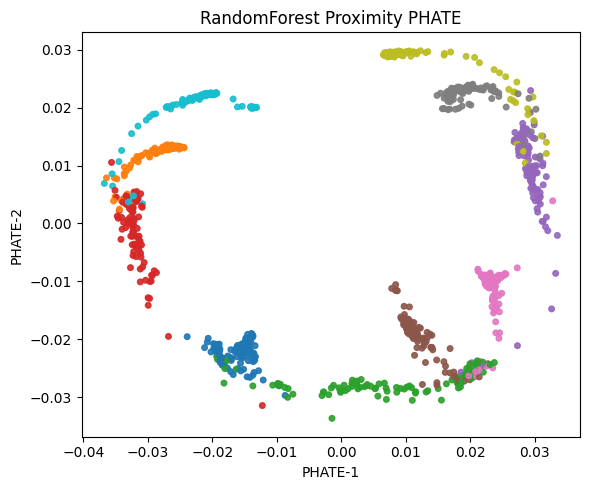

In [19]:
MODEL_MAP = build_model_key_to_class(TASK_TYPE)
results = {}

rf_model, rf_prox = fit_and_get_proximity("RandomForest", MODEL_MAP["RandomForest"], X_train, y_train, TASK_TYPE)
rf_emb = phate_from_proximity(rf_prox, random_state=RANDOM_STATE)
results["RandomForest"] = {"model": rf_model, "proximity": rf_prox, "embedding": rf_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, rf_emb, y_train, "RandomForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 5) ExtraTrees Proximities + PHATE

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.50 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 0.62 seconds.
  Calculating optimal t...
    Automatically selected t = 11
  Calculated optimal t in 1.75 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.13 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 1.26 seconds.
Calculated PHATE in 3.76 seconds.


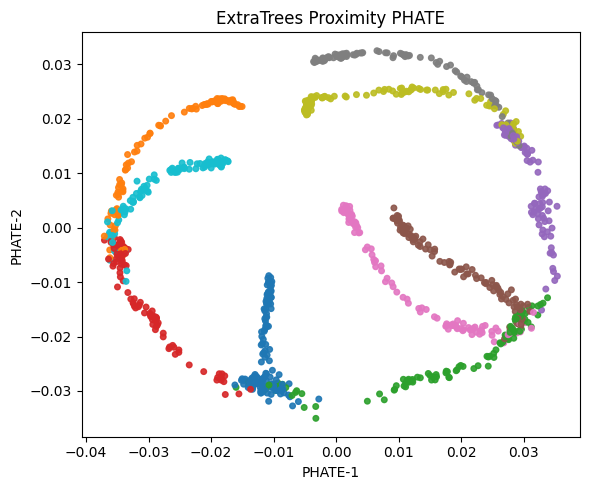

In [20]:
et_model, et_prox = fit_and_get_proximity("ExtraTrees", MODEL_MAP["ExtraTrees"], X_train, y_train, TASK_TYPE)
et_emb = phate_from_proximity(et_prox, random_state=RANDOM_STATE)
results["ExtraTrees"] = {"model": et_model, "proximity": et_prox, "embedding": et_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, et_emb, y_train, "ExtraTrees Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 6) RotationForest Proximities + PHATE
This section runs only when `aeon` is installed.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.54 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 0.65 seconds.
  Calculating optimal t...
    Automatically selected t = 18
  Calculated optimal t in 1.66 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.13 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.31 seconds.
Calculated PHATE in 3.76 seconds.


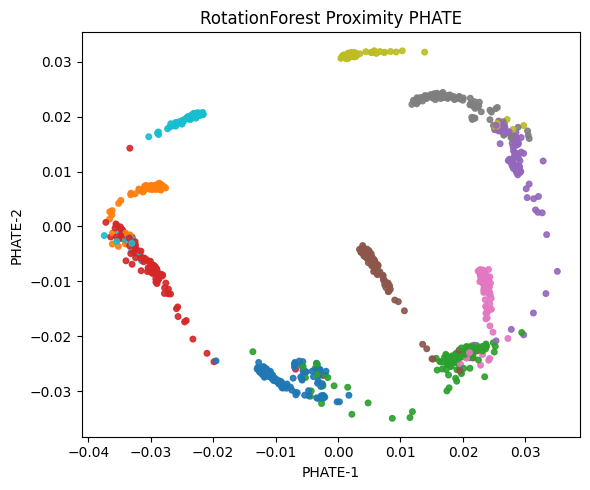

In [21]:
if "RotationForest" in MODEL_MAP:
    rot_model, rot_prox = fit_and_get_proximity("RotationForest", MODEL_MAP["RotationForest"], X_train, y_train, TASK_TYPE)
    rot_emb = phate_from_proximity(rot_prox, random_state=RANDOM_STATE)
    results["RotationForest"] = {"model": rot_model, "proximity": rot_prox, "embedding": rot_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, rot_emb, y_train, "RotationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping RotationForest section because aeon is not installed.")


## 7) IsolationForest Proximities + PHATE
IsolationForest is unsupervised; we still color points by target values for visual comparison.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.66 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.03 seconds.
  Calculated graph and diffusion operator in 0.77 seconds.
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 1.59 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.14 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -3.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 1.34 seconds.
Calculated PHATE in 3.85 seconds.


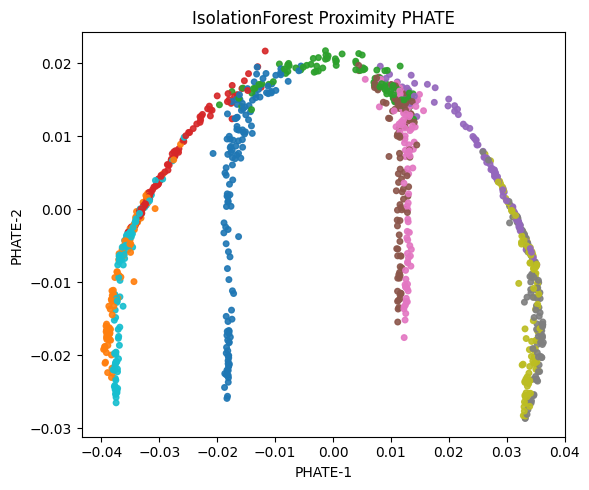

In [22]:
iso_model, iso_prox = fit_and_get_proximity("IsolationForest", MODEL_MAP["IsolationForest"], X_train, y_train, TASK_TYPE)
iso_emb = phate_from_proximity(iso_prox, random_state=RANDOM_STATE)
results["IsolationForest"] = {"model": iso_model, "proximity": iso_prox, "embedding": iso_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, iso_emb, y_train, "IsolationForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 8) ObliqueRandomForest Proximities + PHATE
Oblique splits consider linear combinations of features, enabling more flexible decision boundaries. Requires `scikit-tree`.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.50 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 0.60 seconds.
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 1.76 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.16 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.39 seconds.
Calculated PHATE in 3.91 seconds.


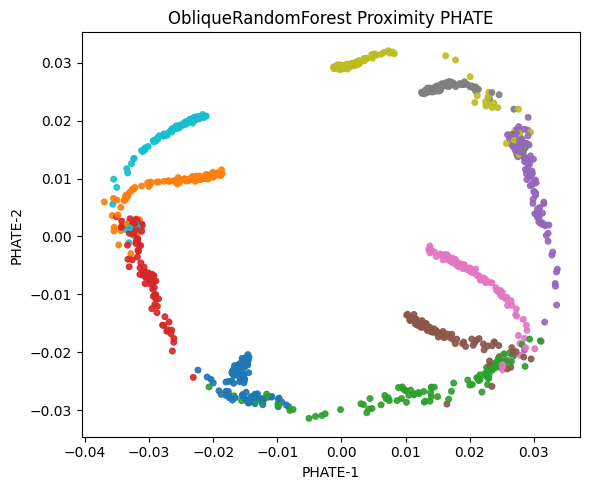

In [23]:
if "ObliqueRandomForest" in MODEL_MAP:
    obl_model, obl_prox = fit_and_get_proximity("ObliqueRandomForest", MODEL_MAP["ObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    obl_emb = phate_from_proximity(obl_prox, random_state=RANDOM_STATE)
    results["ObliqueRandomForest"] = {"model": obl_model, "proximity": obl_prox, "embedding": obl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, obl_emb, y_train, "ObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ObliqueRandomForest section because scikit-tree is not installed.")

## 9) PatchObliqueRandomForest Proximities + PHATE
Patch-oblique trees split on linear combinations within local feature patches. Requires `scikit-tree`.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.74 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 0.85 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 1.74 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.19 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.34 seconds.
Calculated PHATE in 4.13 seconds.


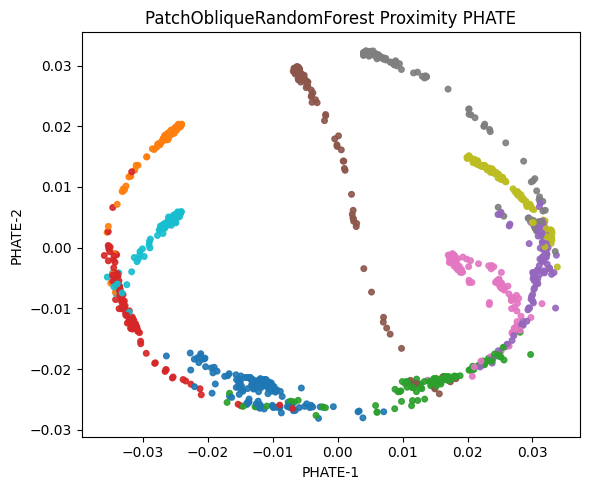

In [24]:
if "PatchObliqueRandomForest" in MODEL_MAP:
    pobl_model, pobl_prox = fit_and_get_proximity("PatchObliqueRandomForest", MODEL_MAP["PatchObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    pobl_emb = phate_from_proximity(pobl_prox, random_state=RANDOM_STATE)
    results["PatchObliqueRandomForest"] = {"model": pobl_model, "proximity": pobl_prox, "embedding": pobl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, pobl_emb, y_train, "PatchObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping PatchObliqueRandomForest section because scikit-tree is not installed.")

## 10) ExtraObliqueRandomForest Proximities + PHATE
Extra-oblique trees add further randomization to the oblique split selection. Requires `scikit-tree`.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.62 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.03 seconds.
  Calculated graph and diffusion operator in 0.73 seconds.
  Calculating optimal t...
    Automatically selected t = 16
  Calculated optimal t in 1.38 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.11 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.5% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 1.45 seconds.
Calculated PHATE in 3.69 seconds.


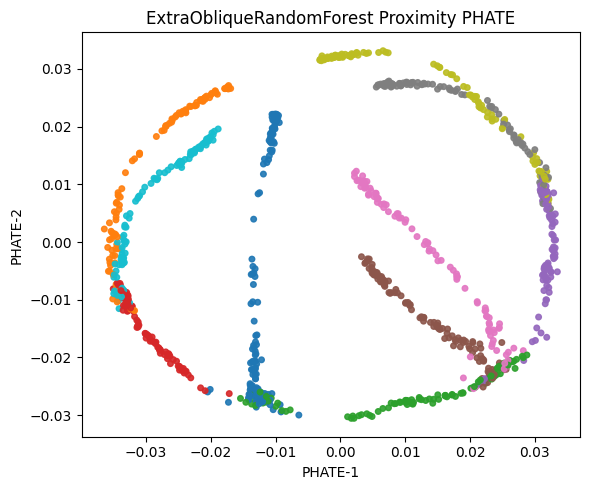

In [25]:
if "ExtraObliqueRandomForest" in MODEL_MAP:
    eobl_model, eobl_prox = fit_and_get_proximity("ExtraObliqueRandomForest", MODEL_MAP["ExtraObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    eobl_emb = phate_from_proximity(eobl_prox, random_state=RANDOM_STATE)
    results["ExtraObliqueRandomForest"] = {"model": eobl_model, "proximity": eobl_prox, "embedding": eobl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, eobl_emb, y_train, "ExtraObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ExtraObliqueRandomForest section because scikit-tree is not installed.")

## 11) HonestForest Proximities + PHATE
Honest forests use separate subsets for structure (splits) and estimation (leaf predictions). Classification only. Requires `scikit-tree`.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.79 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 0.89 seconds.
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 1.89 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.13 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.39 seconds.
Calculated PHATE in 4.31 seconds.


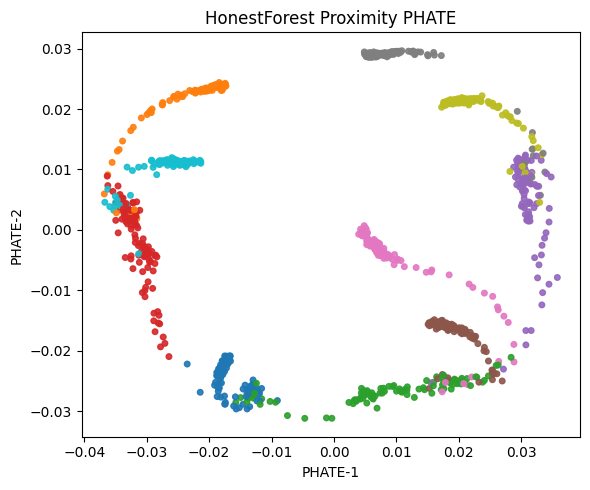

In [26]:
if "HonestForest" in MODEL_MAP:
    hf_model, hf_prox = fit_and_get_proximity("HonestForest", MODEL_MAP["HonestForest"], X_train, y_train, TASK_TYPE)
    hf_emb = phate_from_proximity(hf_prox, random_state=RANDOM_STATE)
    results["HonestForest"] = {"model": hf_model, "proximity": hf_prox, "embedding": hf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, hf_emb, y_train, "HonestForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping HonestForest section (classification only, requires scikit-tree).")

## 12) UnsupervisedRandomForest Proximities + PHATE
Unsupervised random forest learns structure without labels via synthetic target generation. Requires `scikit-tree`.

c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but UnsupervisedRandomForestWithSparseProximity was fitted with feature names
  warnings.warn(


Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 2.99 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.21 seconds.
    Calculating affinities...
    Calculated affinities in 0.48 seconds.
  Calculated graph and diffusion operator in 3.74 seconds.
  Calculating optimal t...
    Automatically selected t = 34
  Calculated optimal t in 8.38 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.86 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 2.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 8.64 seconds.
Calculated PHATE in 21.68 seconds.


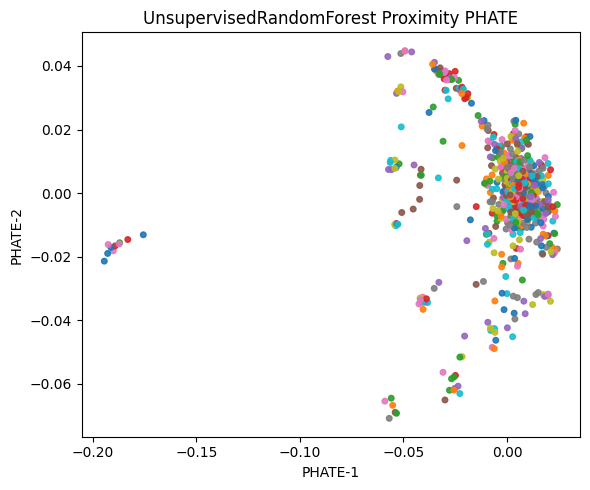

In [27]:
if "UnsupervisedRandomForest" in MODEL_MAP:
    urf_model, urf_prox = fit_and_get_proximity("UnsupervisedRandomForest", MODEL_MAP["UnsupervisedRandomForest"], X_train, y_train, TASK_TYPE)
    urf_emb = phate_from_proximity(urf_prox, random_state=RANDOM_STATE)
    results["UnsupervisedRandomForest"] = {"model": urf_model, "proximity": urf_prox, "embedding": urf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, urf_emb, y_train, "UnsupervisedRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UnsupervisedRandomForest section because scikit-tree is not installed.")

## 13) UnsupervisedObliqueRandomForest Proximities + PHATE
Unsupervised oblique random forest combines oblique (hyperplane) splits with unsupervised learning via synthetic target generation. Requires `scikit-tree`.

c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but UnsupervisedObliqueRandomForestWithSparseProximity was fitted with feature names
  warnings.warn(


Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 3.68 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.22 seconds.
    Calculating affinities...
    Calculated affinities in 0.38 seconds.
  Calculated graph and diffusion operator in 4.32 seconds.
  Calculating optimal t...
    Automatically selected t = 36
  Calculated optimal t in 7.73 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.88 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 2.44 seconds.
Calculated PHATE in 15.40 seconds.


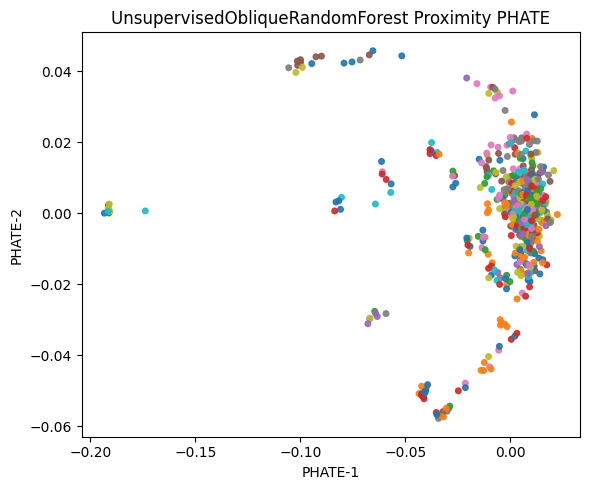

In [28]:
if "UnsupervisedObliqueRandomForest" in MODEL_MAP:
    uorf_model, uorf_prox = fit_and_get_proximity("UnsupervisedObliqueRandomForest", MODEL_MAP["UnsupervisedObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    uorf_emb = phate_from_proximity(uorf_prox, random_state=RANDOM_STATE)
    results["UnsupervisedObliqueRandomForest"] = {"model": uorf_model, "proximity": uorf_prox, "embedding": uorf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, uorf_emb, y_train, "UnsupervisedObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UnsupervisedObliqueRandomForest section because scikit-tree is not installed.")

## 14) ExtendedIsolationForest Proximities + PHATE
Extended isolation forest uses hyperplane splits instead of axis-aligned ones, improving anomaly detection in multi-dimensional data. Requires `scikit-tree`.

Calculating PHATE...
  Running PHATE on 1080 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.95 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 1.06 seconds.
  Calculating optimal t...
    Automatically selected t = 12
  Calculated optimal t in 1.59 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.12 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.33 seconds.
Calculated PHATE in 4.11 seconds.


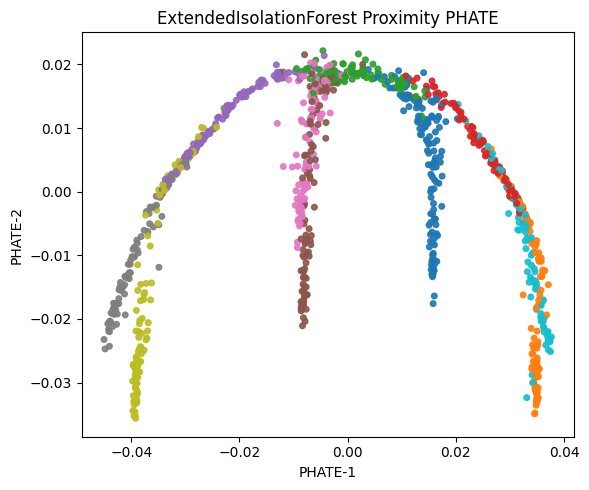

In [30]:
if "ExtendedIsolationForest" in MODEL_MAP:
    eif_model, eif_prox = fit_and_get_proximity("ExtendedIsolationForest", MODEL_MAP["ExtendedIsolationForest"], X_train, y_train, TASK_TYPE)
    eif_emb = phate_from_proximity(eif_prox, random_state=RANDOM_STATE)
    results["ExtendedIsolationForest"] = {"model": eif_model, "proximity": eif_prox, "embedding": eif_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, eif_emb, y_train, "ExtendedIsolationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ExtendedIsolationForest section because scikit-tree is not installed.")

## 15) Final Comparison: All Forest Proximity PHATE Embeddings
This summary figure compares all available model embeddings in one place.

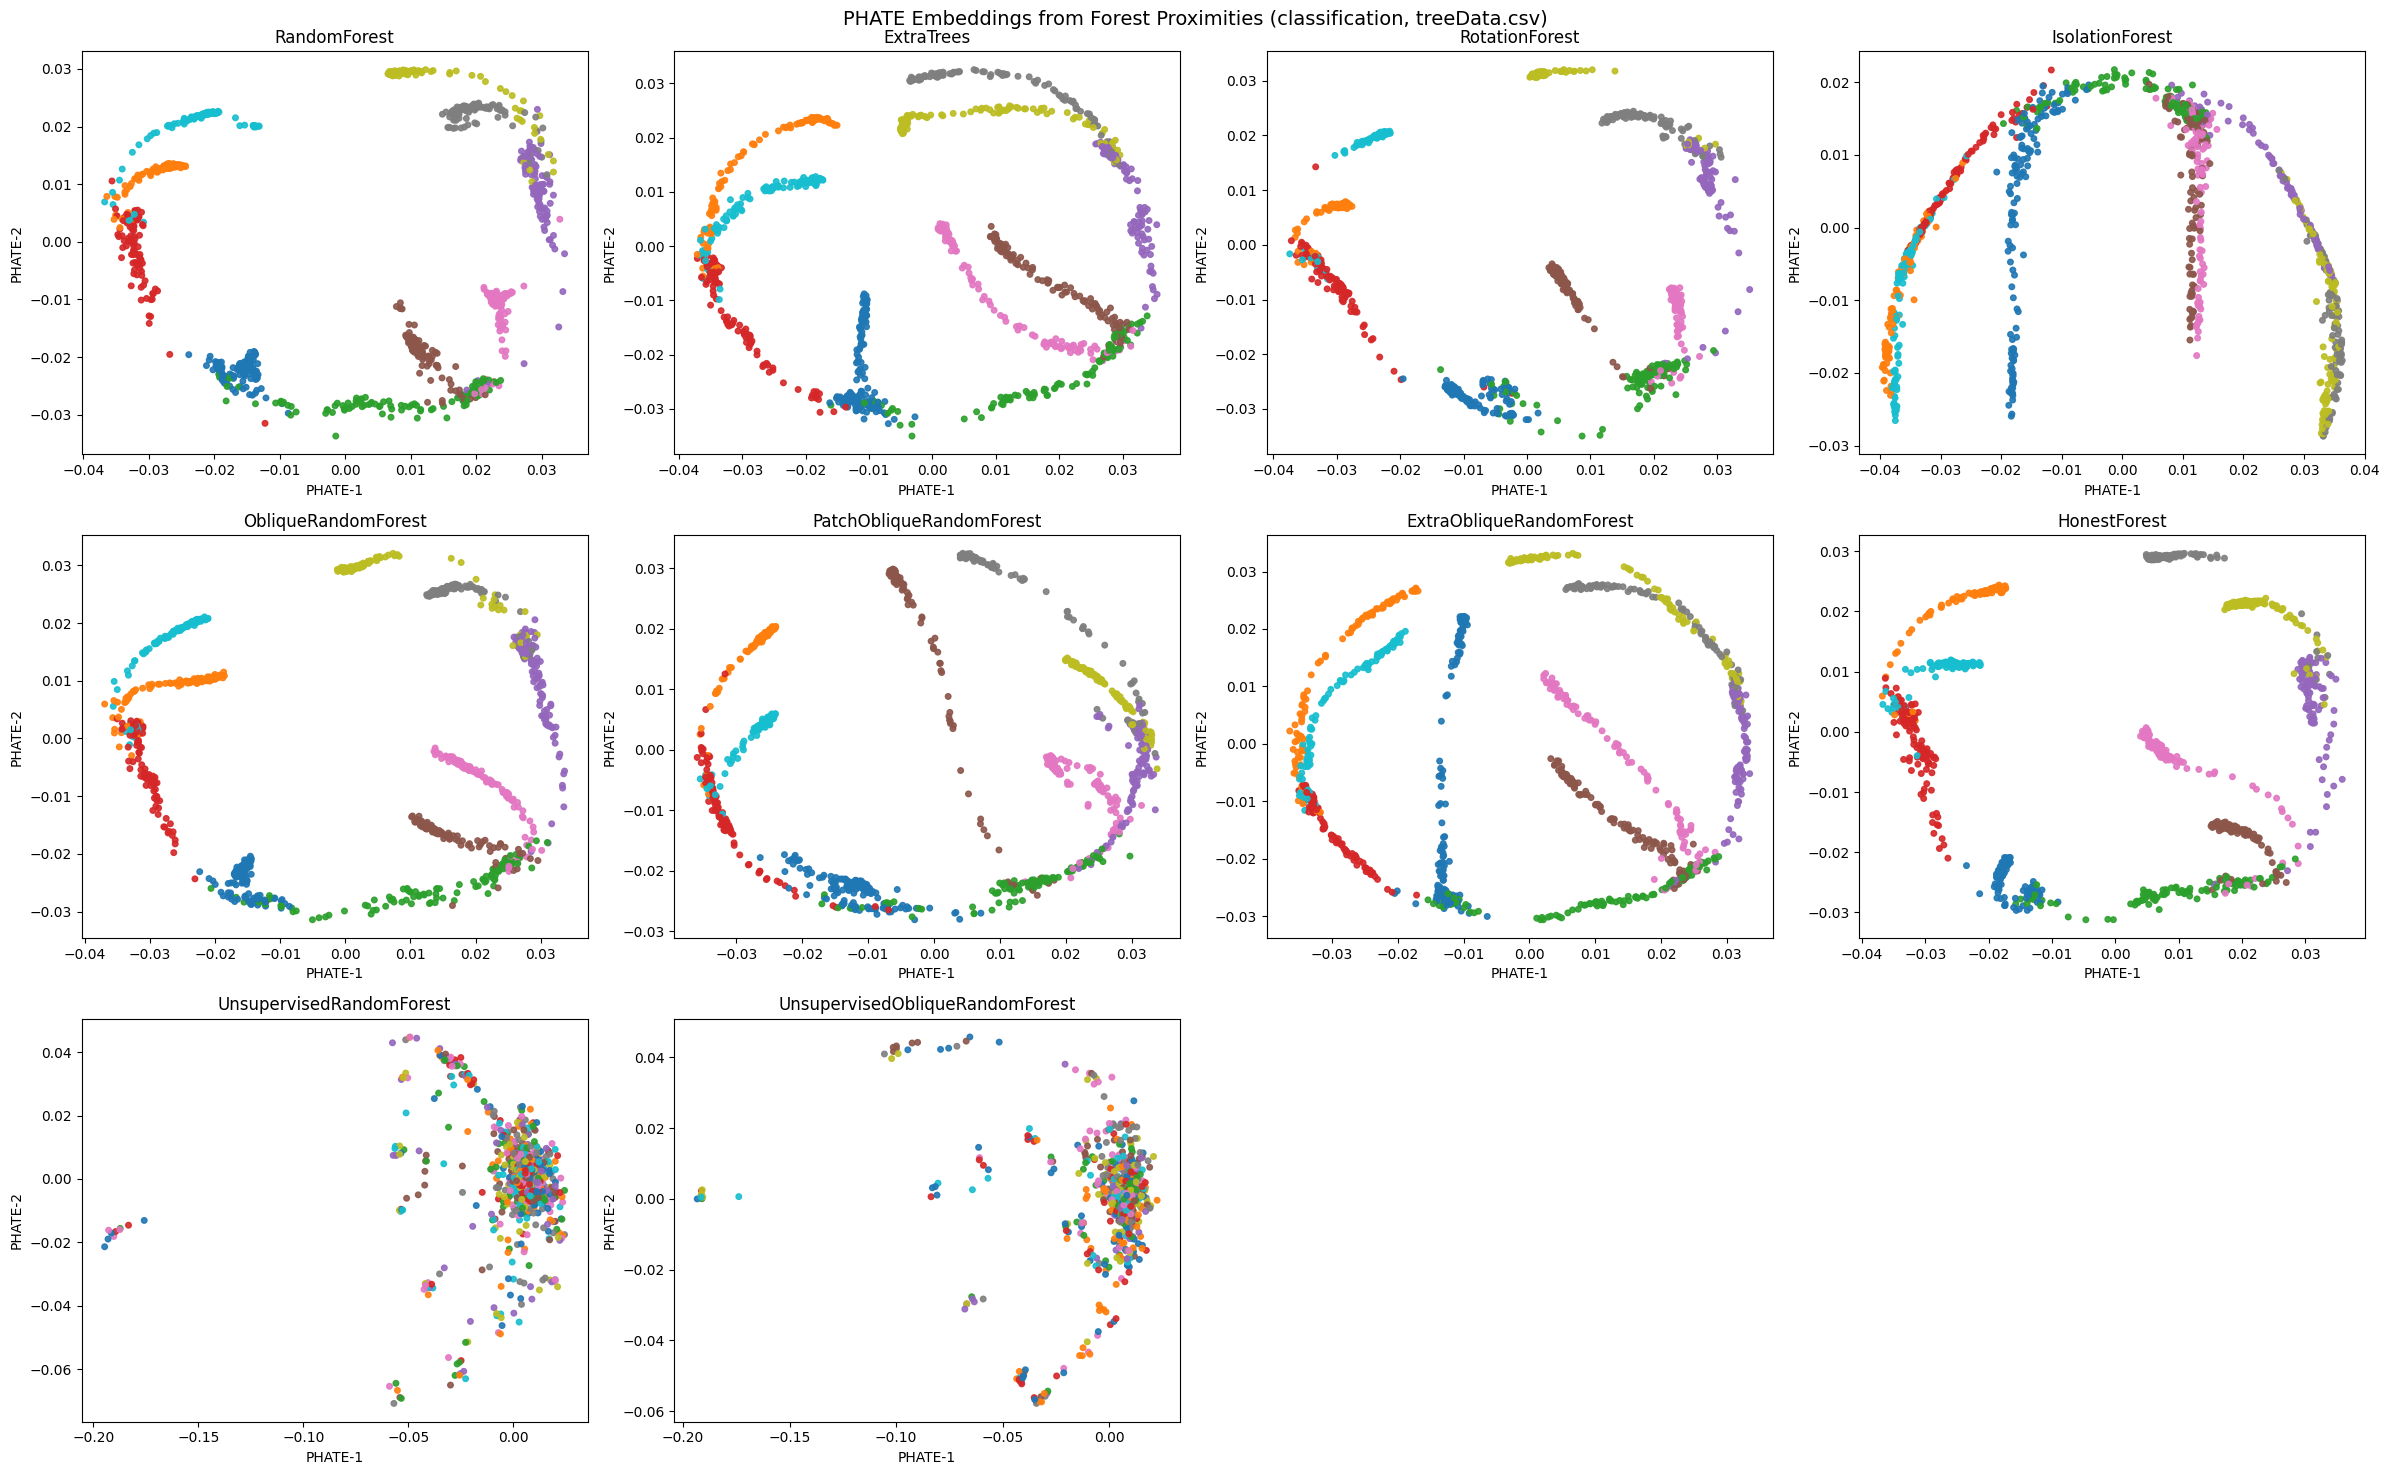

In [29]:
model_order = [
    "RandomForest", "ExtraTrees", "RotationForest", "IsolationForest",
    "ObliqueRandomForest", "PatchObliqueRandomForest", "ExtraObliqueRandomForest",
    "HonestForest", "UnsupervisedRandomForest", "UnsupervisedObliqueRandomForest",
    "ExtendedIsolationForest",
]
available = [m for m in model_order if m in results]
n_models = len(available)

ncols = min(n_models, 4)
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), sharex=False, sharey=False)
axes = np.atleast_1d(axes).ravel()

for i, model_name in enumerate(available):
    ax = axes[i]
    emb = results[model_name]["embedding"]
    plot_embedding(ax, emb, y_train, model_name, TASK_TYPE)

# Hide unused axes
for j in range(n_models, len(axes)):
    axes[j].axis("off")

fig.suptitle(f"PHATE Embeddings from Forest Proximities ({TASK_TYPE}, {dataset_name})", fontsize=14)
plt.tight_layout()
plt.show()